# Drug overdose deaths and suicides in the United States, 2001–2021

Is there a relationship between drug overdose deaths and suicides in the US?
We compare both rates year by year and look at how each one grew.

**Inputs**
- `data/raw/suicide_by_state_2001_2021.csv`: suicide deaths by state and year (CDC, not in GitHub; see the README to download it).
- `data/processed/usa_population.csv`: population by state and year (U.S. Census Bureau).
- `data/processed/drug_overdose_us_2001_2021.csv`: drug overdose deaths per year (NCHS Data Brief 457, extracted with `src/extract_overdose_pdf.py`).
- The *Pulling Data* cell also loads the yearly weather tables and the Spanish suicide data, which are not used in this notebook.

**Outputs.** None: the table and the figure are shown in the notebook.

**Method.** Both rates are crude rates per 10,000 inhabitants. We fit a straight line to the logarithms of both rates (a power law) and show ±1, ±2 and ±3 standard deviations of the residuals around it. Because both rates grow over time, the correlation of the yearly levels is much higher than the correlation of their year-to-year changes.

**How to run.** Open the notebook from the `notebooks/` folder and use *Run All*.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter

In [ ]:
from pathlib import Path

# Repository root: the first folder, going up from this notebook, that contains "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW = ROOT / "data" / "raw"              # original downloads (not uploaded to GitHub)
INTERIM = ROOT / "data" / "interim"      # large intermediate files (not uploaded to GitHub)
PROCESSED = ROOT / "data" / "processed"  # clean tables used in the analysis

## Pulling Data

In [ ]:
WeatherNL = pd.read_csv(PROCESSED / 'NL_yearly.csv')
WeatherUSA = pd.read_csv(PROCESSED / 'usa_yearly.csv')
WeatherESP = pd.read_csv(PROCESSED / 'spain_yearly.csv')
DEsp = pd.read_csv(RAW / 'datos_ine_suicidio_ccaa_desde2001.csv', encoding='latin-1', sep='\t')
DUSA = pd.read_csv(RAW / 'suicide_by_state_2001_2021.csv')

# Used in this notebook
PopUSA = pd.read_csv(PROCESSED / 'usa_population.csv')                  # population by state and year (U.S. Census Bureau)
OverdoseUSA = pd.read_csv(PROCESSED / 'drug_overdose_us_2001_2021.csv')  # overdose deaths per year (NCHS Data Brief 457)

## Rates per 10,000 inhabitants

Overdoses come for the whole country, so we add up the suicides and the population of all states for each year.

In [ ]:
# Total suicides and population of the US for each year
suicides = DUSA.groupby("Year")["Deaths"].sum().rename("suicides")
population = PopUSA.groupby("year")["population"].sum()

# One table with one row per year
d = OverdoseUSA.set_index("year").join(suicides).join(population)

# Deaths per 10,000 inhabitants
d["overdose_per_10k"] = d["deaths_total"] / d["population"] * 10000
d["suicides_per_10k"] = d["suicides"] / d["population"] * 10000

d[["deaths_total", "suicides", "population", "overdose_per_10k", "suicides_per_10k"]]

,deaths_total,suicides,population,overdose_per_10k,suicides_per_10k
year,,,,,
2001,19394,30622,284968955,0.680565,1.074573
2002,23518,31655,287625193,0.817661,1.100564
2003,25785,31484,290107933,0.888807,1.085251
2004,27424,32439,292805298,0.936595,1.107869
2005,29813,32637,295516599,1.008843,1.104405
2006,34425,33300,298379912,1.153730,1.116027
2007,36010,34598,301231207,1.195427,1.148553
2008,36450,36035,304093966,1.198643,1.184996
2009,37004,36909,306771529,1.206240,1.203143


## Fit in log–log

We fit a straight line to the logarithms of both rates (a power law).
The slope says how much suicides grow when overdoses grow, and the standard deviation of the residuals says how far the years are from the line.

In [ ]:
lx = np.log10(d["overdose_per_10k"])
ly = np.log10(d["suicides_per_10k"])

slope, intercept = np.polyfit(lx, ly, 1)               # straight line in log-log
r = np.corrcoef(lx, ly)[0, 1]                           # correlation
std = np.std(ly - (intercept + slope * lx), ddof=2)     # spread of the points around the line

print(f"Slope = {slope:.2f}   R² = {r**2:.2f}   std of residuals = {std:.3f}")

Slope = 0.25   R² = 0.85   std of residuals = 0.019


## Plots

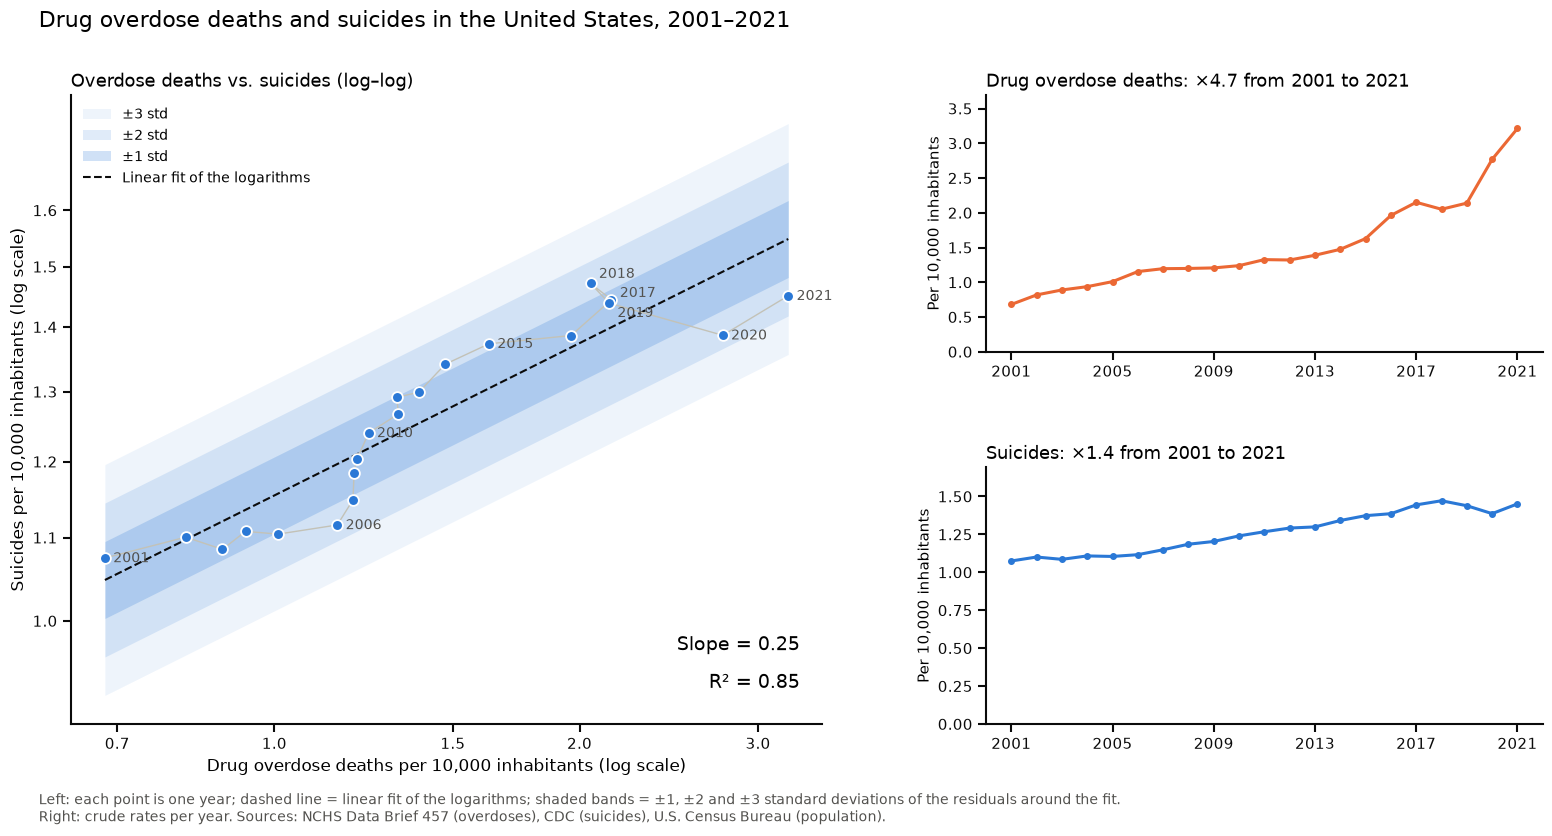

In [ ]:
BLUE, ORANGE, INK, INK2 = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"

def style(ax):
    # Visible axes and no grid
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(INK)
        ax.spines[side].set_linewidth(1.5)
    ax.tick_params(colors=INK, width=1.5, length=6, labelsize=11)

fig = plt.figure(figsize=(16, 8.5))
grid = fig.add_gridspec(2, 2, width_ratios=[1.35, 1], hspace=0.45, wspace=0.25)
ax = fig.add_subplot(grid[:, 0])      # left: overdoses vs suicides
ax_od = fig.add_subplot(grid[0, 1])   # top right: overdoses over time
ax_su = fig.add_subplot(grid[1, 1])   # bottom right: suicides over time

# Left plot: log-log scale
ax.set_xscale("log")
ax.set_yscale("log")

# Fitted line with faded bands of ±1, ±2 and ±3 standard deviations
x = np.logspace(lx.min(), lx.max(), 100)
y = intercept + slope * np.log10(x)
for k, alpha in [(3, 0.08), (2, 0.14), (1, 0.22)]:
    ax.fill_between(x, 10 ** (y - k * std), 10 ** (y + k * std), color=BLUE, alpha=alpha, lw=0, label=f"±{k} std", zorder=1)
ax.plot(x, 10 ** y, color=INK, lw=1.5, ls="--", zorder=2, label="Linear fit of the logarithms")

# One point per year, joined in order
ax.plot(d["overdose_per_10k"], d["suicides_per_10k"], color="#c3c2b7", lw=1, zorder=3)
ax.scatter(d["overdose_per_10k"], d["suicides_per_10k"], s=60, color=BLUE, edgecolor="white", lw=1.3, zorder=4)
offsets = {2017: (6, 2), 2018: (6, 4), 2019: (6, -10)}
for year in [2001, 2006, 2010, 2015, 2017, 2018, 2019, 2020, 2021]:
    ax.annotate(str(year), (d.loc[year, "overdose_per_10k"], d.loc[year, "suicides_per_10k"]),
                xytext=offsets.get(year, (6, -3)), textcoords="offset points", fontsize=10, color=INK2, zorder=5)

# Plain numbers on the log axes
ax.xaxis.set_major_locator(FixedLocator([0.7, 1, 1.5, 2, 3]))
ax.yaxis.set_major_locator(FixedLocator([1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6]))
for axis in (ax.xaxis, ax.yaxis):
    axis.set_major_formatter(ScalarFormatter())
    axis.set_minor_locator(NullLocator())

style(ax)
ax.set_xlabel("Drug overdose deaths per 10,000 inhabitants (log scale)", fontsize=12)
ax.set_ylabel("Suicides per 10,000 inhabitants (log scale)", fontsize=12)
ax.text(0.97, 0.11, f"Slope = {slope:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=14)
ax.text(0.97, 0.05, f"R² = {r**2:.2f}", transform=ax.transAxes, ha="right", va="bottom", fontsize=14)
ax.legend(loc="upper left", frameon=False, fontsize=10)
ax.set_title("Overdose deaths vs. suicides (log–log)", fontsize=13, loc="left")

# Right plots: growth of each rate over time
for a, col, color, title in [(ax_od, "overdose_per_10k", ORANGE, "Drug overdose deaths"),
                             (ax_su, "suicides_per_10k", BLUE, "Suicides")]:
    a.plot(d.index, d[col], color=color, lw=2.2, marker="o", ms=4)
    a.set_ylim(0, d[col].max() * 1.15)
    a.set_xticks(range(2001, 2022, 4))
    style(a)
    growth = d[col].iloc[-1] / d[col].iloc[0]          # how many times it grew from 2001 to 2021
    a.set_title(f"{title}: ×{growth:.1f} from 2001 to 2021", fontsize=13, loc="left")
    a.set_ylabel("Per 10,000 inhabitants", fontsize=11)

fig.suptitle("Drug overdose deaths and suicides in the United States, 2001–2021", fontsize=16, x=0.04, ha="left")

# Caption below the plots
fig.text(0.04, 0.02,
         "Left: each point is one year; dashed line = linear fit of the logarithms; shaded bands = ±1, ±2 and ±3 standard deviations of the residuals around the fit.\n"
         "Right: crude rates per year. Sources: NCHS Data Brief 457 (overdoses), CDC (suicides), U.S. Census Bureau (population).",
         fontsize=10, color=INK2, va="bottom")
fig.subplots_adjust(top=0.88, left=0.06, right=0.98, bottom=0.14)
plt.show()